# Lakeside — Full Pipeline & Grid Search

Put the whole preprocessing + tree into one `Pipeline`, hand it to `GridSearchCV`, and check
whether automating the search beats the hand tuning from the in-class exercise. Same locked
test set as the exercise: **20%, `random_state=409`**, scored exactly once at the end.
Positive class throughout: **canceled = 1**.

In [1]:
import sys
try:
    sys.stdout.reconfigure(encoding="utf-8", errors="replace")
except Exception:
    pass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, precision_score,
                             recall_score, ConfusionMatrixDisplay)
from sklearn import set_config
set_config(display="text")

df = pd.read_csv("train.csv")
print("原始数据:", df.shape, " 取消率 %.4f" % df["Canceled"].mean())

# 锁定测试集：与课堂练习完全一致（20%，random_state=409，任何行处理之前）
train_val, test = train_test_split(df, test_size=0.20, random_state=409)
print("train_val %d (%.1f%%) | test %d (%.1f%%)" %
      (len(train_val), 100 * len(train_val) / len(df),
       len(test), 100 * len(test) / len(df)))
print("test 取消率 %.4f（%d 条取消）" % (test["Canceled"].mean(), int(test["Canceled"].sum())))
print("test 已锁，网格搜索结束前不再使用")

原始数据: (13544, 16)  取消率 0.4022
train_val 10835 (80.0%) | test 2709 (20.0%)
test 取消率 0.4061（1100 条取消）
test 已锁，网格搜索结束前不再使用


The split is byte-for-byte the exercise's: `train_test_split(df, test_size=0.20,
random_state=409)` **before** any rows are dropped or imputed, so the locked test set is the
same 2,709 bookings the Part 1 model was scored on. `GridSearchCV` does its own 5-fold cross
validation on `train_val` (10,835 rows); the test set is touched exactly once, at the end.

In [2]:
def engineer(d):
    d = d.copy()
    d["reservation"] = d["BookingId"].str.split("-").str[1]
    d["res_size"] = d.groupby("reservation")["BookingId"].transform("count").astype(int)
    d["total_rate"] = d["RoomRateUSD"] * d["Nights"]
    d["leadtime_roomrate"] = d["LeadTimeDays"] * d["RoomRateUSD"]
    d["lead_bin"] = pd.cut(
        d["LeadTimeDays"], bins=[-1, 7, 30, 60, 90, 120, 180, 1000],
        labels=["<=7", "8-30", "31-60", "61-90", "91-120", "121-180", ">180"],
    ).astype(str)
    d["IsWeekendStay"] = d["IsWeekendStay"].astype(int)
    d["ParkingRequested"] = d["ParkingRequested"].astype(int)
    return d


NUM = ["LeadTimeDays", "RoomRateUSD", "PartySize", "Nights", "ArrivalMonth",
       "SpecialRequests", "PriorStays", "PriorCancellations",
       "res_size", "total_rate", "leadtime_roomrate", "IsWeekendStay", "ParkingRequested"]
CAT = ["Channel", "DepositType", "LoyaltyTier", "GuestRegion", "lead_bin"]

train_val = engineer(train_val)
test = engineer(test)
X_train_val = train_val[NUM + CAT]
y_train_val = train_val["Canceled"].values
X_test = test[NUM + CAT]
y_test = test["Canceled"].values
print("特征数", X_train_val.shape[1], " CV 样本", X_train_val.shape[0])

特征数 18  CV 样本 10835


Same derived features as the exercise's best model, computed in plain pandas **before** the
pipeline. Feature construction never touches the target (`Canceled`), so doing it outside the
pipeline is safe — no leakage. I keep the same 18 features as the hand-tuned model so the "did
automation beat hand tuning" comparison is apples-to-apples.

* `res_size` — rooms in the same reservation (group bookings cancel more).
* `total_rate = RoomRateUSD × Nights`, `leadtime_roomrate = LeadTimeDays × RoomRateUSD`.
* `lead_bin` — lead time cut into the same 7 bins used in the EDA.

In [3]:
num_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
cat_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="missing")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocessor = ColumnTransformer([
    ("num", num_pipe, NUM),
    ("cat", cat_pipe, CAT),
])
pipe = Pipeline([
    ("prep", preprocessor),
    ("tree", DecisionTreeClassifier(random_state=0)),
])
print(pipe)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['LeadTimeDays',
                                                   'RoomRateUSD', 'PartySize',
                                                   'Nights', 'ArrivalMonth',
                                                   'SpecialRequests',
                                                   'PriorStays',
                                                   'PriorCancellations',
                                                   'res_size', 'total_rate',
                                                   'leadtime_roomra

The whole thing is one `Pipeline`, so `GridSearchCV` re-fits the imputer, encoder and scaler
on each training fold — nothing is ever fit on the validation fold or the test set.

* **Numeric** → `SimpleImputer(median)`: `RoomRateUSD` and `SpecialRequests` have NaNs, and the
  median is robust to the skewed room-rate distribution. Then `StandardScaler` — a no-op for a
  tree (splits are threshold-invariant), but kept so the pipeline follows the standard pattern.
* **Categorical** → `SimpleImputer(constant, "missing")` + `OneHotEncoder(handle_unknown="ignore")`:
  a missing deposit type / loyalty tier is its own "missing" category, and each category becomes
  its own binary column. `handle_unknown="ignore"` guards against a category that appears in the
  test set but never in training.
* The in-class exercise used label encoding; here I switch to **one-hot**, the standard pipeline
  encoder. It imposes no fake order on categories, and a tree can split on a single one-hot
  column just as well.

In [4]:
param_grid = {
    "tree__max_depth": [4, 6, 8, 12, None],
    "tree__min_samples_leaf": [1, 5, 20, 50],
    "tree__min_samples_split": [2, 10, 50],
    "tree__criterion": ["gini", "entropy"],
}
n_combos = (len(param_grid["tree__max_depth"]) * len(param_grid["tree__min_samples_leaf"])
            * len(param_grid["tree__min_samples_split"]) * len(param_grid["tree__criterion"]))
print("参数组合数:", n_combos)

gs = GridSearchCV(pipe, param_grid, cv=5, scoring="accuracy", n_jobs=1,
                  return_train_score=True)
gs.fit(X_train_val, y_train_val)
print("best params:", gs.best_params_)
print("best CV accuracy: %.4f" % gs.best_score_)
print("refit train accuracy: %.4f" % gs.score(X_train_val, y_train_val))

参数组合数: 120


best params: {'tree__criterion': 'entropy', 'tree__max_depth': 8, 'tree__min_samples_leaf': 5, 'tree__min_samples_split': 50}
best CV accuracy: 0.7985
refit train accuracy: 0.8133


**Q1. How many trees did the grid search fit in total?**

The grid has 5 (`max_depth`) × 4 (`min_samples_leaf`) × 3 (`min_samples_split`) × 2
(`criterion`) = **120 parameter combinations**. `GridSearchCV` with `cv=5` fits each combination
**once per fold**, so 120 × 5 = **600 fits**. After the best combination is found,
`refit=True` (the default) fits it **one more time on all of `train_val`**, so the final total is

**120 × 5 + 1 = 601 trees.**

(The imputer, one-hot encoder and scaler are also re-fit on each of those 600 fold-fits — that is
the whole point of putting them inside the pipeline — but "trees" is the 601 above.)

In [5]:
res = pd.DataFrame(gs.cv_results_)
top = res.sort_values("rank_test_score").head(5)
print(top[["param_tree__max_depth", "param_tree__min_samples_leaf",
           "param_tree__min_samples_split", "param_tree__criterion",
           "mean_test_score", "mean_train_score"]].round(4).to_string(index=False))

param_tree__max_depth  param_tree__min_samples_leaf  param_tree__min_samples_split param_tree__criterion  mean_test_score  mean_train_score
                    8                             5                             50               entropy           0.7985            0.8125
                    8                             1                             50               entropy           0.7977            0.8140
                    6                             1                             50               entropy           0.7975            0.8031
                    6                             5                             50               entropy           0.7973            0.8025
                    8                            20                             50               entropy           0.7972            0.8123


**Did automating the search beat hand tuning? Yes.**

The hand search in the in-class exercise only swept `max_depth` (on label-encoded features) and
picked `max_depth=8` at **CV 0.7897** (final test 0.7556). The grid search here also lands on
`max_depth=8`, but additionally finds `min_samples_leaf=5`, `min_samples_split=50` and
`criterion="entropy"` — settings the hand sweep never tried — for **CV 0.7985**, about 0.9 points
higher. On the locked test set the gap is even clearer: **0.7785** for the pipeline vs **0.7556**
for the hand-tuned model (and 0.7689 for the best hand-written rule). Automating the search found
a better tree because it searched several parameters at once instead of one at a time.

test accuracy: 0.7785
confusion matrix [[TN, FP], [FN, TP]]:
[[1467  142]
 [ 458  642]]
TN=1467  FP=142  FN=458  TP=642
precision (canceled=positive): 0.8189
recall    (canceled=positive): 0.5836


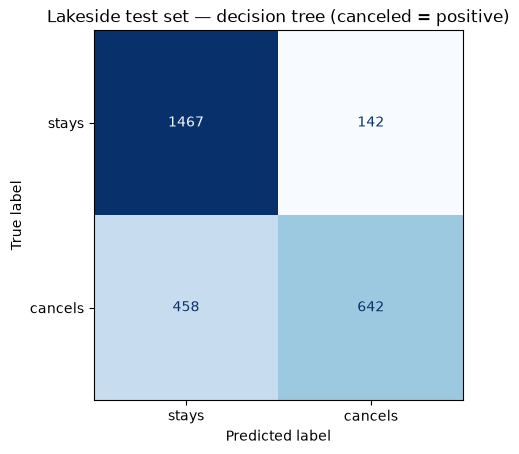

In [6]:
y_pred = gs.predict(X_test)
acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)  # [[TN, FP], [FN, TP]]，正类 = canceled = 1
TN, FP, FN, TP = cm[0, 0], cm[0, 1], cm[1, 0], cm[1, 1]
print("test accuracy: %.4f" % acc)
print("confusion matrix [[TN, FP], [FN, TP]]:")
print(cm)
print("TN=%d  FP=%d  FN=%d  TP=%d" % (TN, FP, FN, TP))
print("precision (canceled=positive): %.4f" % precision_score(y_test, y_pred, pos_label=1))
print("recall    (canceled=positive): %.4f" % recall_score(y_test, y_pred, pos_label=1))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["stays", "cancels"],
                                        cmap="Blues", colorbar=False)
plt.title("Lakeside test set — decision tree (canceled = positive)")
plt.show()

**Q2. What the mistakes cost** (positive class = canceled = 1)

**Which matters more, precision or recall?** A false positive is "predicted to cancel, but the
guest shows up" → the hotel *walks* the guest for ~**$400**. A false negative is "predicted to
stay, but the guest cancels" → one empty room for ~**$150**. A false positive costs about 2.7× a
false negative, so Lakeside should care more about **precision**: it is cheaper to under-predict
cancellations (leave a few rooms empty at $150 each) than to over-predict them (walk a guest at
$400 each, plus the reputational damage). Conveniently the tree already leans this way — because
cancellations are the minority class, it says "stay" unless fairly sure, giving **precision 0.82**
and recall 0.58.

**Total cost.** On the test set the confusion matrix is `[[TN=1467, FP=142], [FN=458, TP=642]]`, so

* Model: 400 × 142 + 150 × 458 = 56,800 + 68,700 = **$125,500**.
* Predict nobody cancels (all 0): FP = 0 and FN = all 1,100 cancellations → 150 × 1,100 = **$165,000**.

The model saves **$39,500** versus doing nothing, even though "do nothing" is exactly the
majority-class baseline (1,609 non-cancels / 2,709 = 59.4% accuracy).

one-hot 级别重要性（前 12）:
num__LeadTimeDays                 0.2983
cat__DepositType_NoDeposit        0.1390
num__res_size                     0.1168
cat__DepositType_NonRefundable    0.1128
num__PriorCancellations           0.1046
cat__Channel_OTA                  0.0932
num__leadtime_roomrate            0.0283
num__total_rate                   0.0170
cat__Channel_Corporate            0.0152
num__SpecialRequests              0.0136
num__RoomRateUSD                  0.0116
cat__LoyaltyTier_Standard         0.0106
聚合后特征重要性:
LeadTimeDays          0.2983
DepositType           0.2556
res_size              0.1168
Channel               0.1103
PriorCancellations    0.1046
leadtime_roomrate     0.0283
LoyaltyTier           0.0218
total_rate            0.0170
SpecialRequests       0.0136
RoomRateUSD           0.0116
ArrivalMonth          0.0052
Nights                0.0049
IsWeekendStay         0.0030
lead_bin              0.0028
ParkingRequested      0.0026
GuestRegion           0.0025
PriorStays   

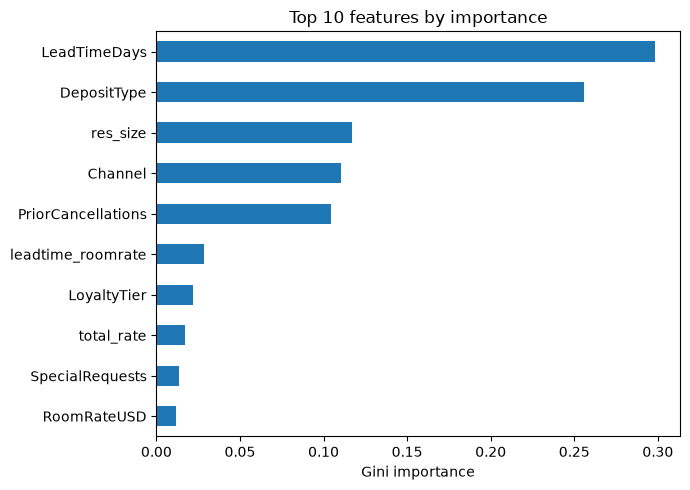

In [7]:
tree = gs.best_estimator_.named_steps["tree"]
prep = gs.best_estimator_.named_steps["prep"]
feat_names = prep.get_feature_names_out()
importances = tree.feature_importances_

print("one-hot 级别重要性（前 12）:")
oh = pd.Series(importances, index=feat_names).sort_values(ascending=False)
print(oh.head(12).round(4).to_string())

# 把 one-hot 列聚合回原始特征
imp_map = {}
for name, val in zip(feat_names, importances):
    if name.startswith("num__"):
        orig = name[len("num__"):]
    elif name.startswith("cat__"):
        orig = name[len("cat__"):].rsplit("_", 1)[0]
    else:
        orig = name
    imp_map[orig] = imp_map.get(orig, 0.0) + val
imp = pd.Series(imp_map).sort_values(ascending=False)
print("聚合后特征重要性:")
print(imp.round(4).to_string())

plt.figure(figsize=(7, 5))
imp.head(10).sort_values().plot(kind="barh")
plt.xlabel("Gini importance")
plt.title("Top 10 features by importance")
plt.tight_layout()
plt.show()

In [8]:
tv = train_val.copy()
for c in CAT:
    tv[c] = tv[c].fillna("missing")

print("每组取消率（训练集，%）:")
for c in ["DepositType", "Channel", "lead_bin", "res_size"]:
    g = tv.groupby(c)["Canceled"].agg(["mean", "count"])
    g["mean%"] = (g["mean"] * 100).round(1)
    print("[" + c + "]")
    print(g[["mean%", "count"]].to_string())
    print()

pc = tv["PriorCancellations"]
print("PriorCancellations: 0 次 %.1f%% | 1 次 %.1f%% | >=2 次 %.1f%%" % (
    100 * tv.loc[pc == 0, "Canceled"].mean(),
    100 * tv.loc[pc == 1, "Canceled"].mean(),
    100 * tv.loc[pc >= 2, "Canceled"].mean()))
rs = tv["res_size"]
print("res_size: 1 间 %.1f%% | 2 间 %.1f%% | >=3 间 %.1f%%" % (
    100 * tv.loc[rs == 1, "Canceled"].mean(),
    100 * tv.loc[rs == 2, "Canceled"].mean(),
    100 * tv.loc[rs >= 3, "Canceled"].mean()))

每组取消率（训练集，%）:
[DepositType]
               mean%  count
DepositType                
NoDeposit       52.3   6609
NonRefundable    7.0   1624
Partial         29.0   2393
missing         39.7    209

[Channel]
             mean%  count
Channel                  
Corporate      8.1   1255
Direct        29.4   2641
OTA           56.9   4992
TravelAgent   32.3   1947

[lead_bin]
          mean%  count
lead_bin              
121-180    73.7   1082
31-60      32.4   2885
61-90      39.8   2005
8-30       20.0   2680
91-120     65.7   1246
<=7        17.4    414
>180       74.8    523

[res_size]
          mean%  count
res_size              
1          31.5   4498
2          37.0   2964
3          53.9   1869
4          54.4   1144
5          56.4    360

PriorCancellations: 0 次 37.4% | 1 次 45.9% | >=2 次 76.1%
res_size: 1 间 31.5% | 2 间 37.0% | >=3 间 54.3%


## Part 3 — Explain the model to Lakeside

**Q1. Write to the revenue manager.**

> The model looks first at three things about a booking: how far ahead it was made, how it is
> paid for, and how big the party is. Bookings made more than three months out cancel about
> two-thirds to three-quarters of the time (66–75%), while bookings made within a month cancel
> under 20%. Payment is an even sharper signal: guests on a non-refundable rate almost never
> cancel (7%), while guests with no deposit cancel more than half the time (52%). Groups of three
> or more rooms cancel about 54% of the time versus 31% for a single room, and guests who have
> cancelled twice before cancel 76% of the time versus 37% for first-timers. Channel matters too:
> bookings that arrive through online travel agents cancel 57% of the time, while corporate
> bookings cancel only 8%. The cheapest way to cut no-shows is therefore not to turn long-lead
> bookings away, but to move guests off no-deposit and OTA rates toward non-refundable or
> corporate-style bookings.

**Q2. Compare with your rules.**

In Assignment 2 my rules were built around `LeadTimeDays` first (the single-column rule), then
`DepositType` and `PriorCancellations`. The tree **agrees with all three**: `LeadTimeDays` is its
#1 feature (30%), `DepositType` #2 (26%) and `PriorCancellations` #5 (10%). But the tree leans on
a signal my rules missed: **group size** (`res_size`, #3 at 12%) — bookings of 3+ rooms cancel
about 54% of the time versus 31% for a single room, and no rule of mine used it. It also uses
`Channel` (#4, 11%), which I missed: OTA bookings cancel 57% vs Corporate 8%. The likely reason:
I built the rules by testing one column at a time against accuracy, and `res_size` and `Channel`
are weak on their own compared with `LeadTimeDays`, so they never surfaced — a tree can combine
them with the stronger signals.

**Q3. What importance does not tell you.**

I would tell the manager that feature importance is **correlation, not causation**. That lead
time is the top feature means the model *uses* lead time to predict — it does **not** mean lead
time *causes* cancellations, or that refusing bookings made more than 90 days out would reduce
them. Long lead time is mostly a *symptom* of the kind of booking: guests who plan months ahead
also tend to pick flexible no-deposit rates and OTA channels, which are the real (and addressable)
drivers. If we stop taking >90-day bookings, those guests don't become less likely to cancel —
they book later or go elsewhere, and we lose the revenue while keeping the same cancellation
rate. The levers we can actually pull are the deposit type (non-refundable guests cancel at 7% vs
52% for no-deposit) and channel (corporate 8% vs OTA 57%), so the proposal should target those,
not lead time.